Laboratorio de clasificacion

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
np.random.seed(200831)

In [4]:
voice = pd.read_csv("voice.csv")

In [5]:
voice.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [6]:
#voice.rename(columns={column: column.lower() for column in voice.columns.values}, inplace=True)
voice.columns = voice.columns.astype(str).str.lower()

In [7]:
voice.columns.values

array(['meanfreq', 'sd', 'median', 'q25', 'q75', 'iqr', 'skew', 'kurt',
       'sp.ent', 'sfm', 'mode', 'centroid', 'meanfun', 'minfun', 'maxfun',
       'meandom', 'mindom', 'maxdom', 'dfrange', 'modindx', 'label'],
      dtype=object)

1. ¿Cuántas observaciones tienes en el conjunto de entrenamiento? ¿Cuántas observaciones tienes en el conjunto de pruebas?


In [8]:
X = voice.drop(['label'], axis=1)
y = voice.label

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
train_x, test_x, train_y, test_y = train_test_split(X, y, test_size=0.3)

In [11]:
print("train: ", train_x.shape[0], "\ntest: ", test_x.shape[0])

train:  2217 
test:  951


2. GridSearchCV 

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [ ]:
rf = RandomForestClassifier( random_state = 42 )

In [ ]:
grid = {'n_estimators': [700, 800, 1000], 
        'criterion': ["gini", "entropy"],
        "min_samples_leaf": [5, 7, 9, 11]}

In [16]:
gs = GridSearchCV(rf, param_grid=grid, cv=10, scoring="accuracy", n_jobs=-1)

In [17]:
gs.fit(train_x, train_y)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'min_samples_leaf': [5, 7, ...], 'n_estimators': [700, 800, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,800


3. ¿Cuántos modelos se entrenaron?
 24

4. ¿Cuál es el mejor estimador encontrado por el GridSearchCV? Incluye los valores de cada parámetro

In [18]:
model = gs.best_estimator_
model

,n_estimators,800
,criterion,'entropy'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


    a. ¿Cuál es el mejor score del mejor estimador?

In [19]:
gs.best_score_

np.float64(0.9801577595695242)

5. ¿Cuáles son las tres variables que brindan más información del mejor estimador obtenido con el GridSearchCV? Incluye el porcentaje de importancia


In [20]:
model.feature_importances_

array([0.01608315, 0.07954933, 0.01184833, 0.12349111, 0.01059768,
       0.19039664, 0.01034881, 0.00927797, 0.03982227, 0.03298231,
       0.01734087, 0.01728806, 0.38997713, 0.00816885, 0.00453857,
       0.0076598 , 0.00673351, 0.00957494, 0.00913899, 0.00518171])

In [21]:
feature_importance = pd.DataFrame({'feature': train_x.columns.values, 
                                  'importance': model.feature_importances_})

In [25]:
feature_importance.sort_values(by="importance", ascending=False).head()

,feature,importance
12,meanfun,0.389977
5,iqr,0.190397
3,q25,0.123491
1,sd,0.079549
8,sp.ent,0.039822


In [26]:
feature_importance.tail()

,feature,importance
15,meandom,0.007660
16,mindom,0.006734
17,maxdom,0.009575
18,dfrange,0.009139
19,modindx,0.005182


6. Predicciones con el mejor estimador de la última observación

In [27]:
gs.predict(test_x.tail(1))

array(['female'], dtype=object)

In [28]:
gs.predict_proba(test_x.tail(1))

array([[0.89932366, 0.10067634]])

7. Predicciones con el mejor estimado 

In [29]:
prediction_labels = gs.predict(test_x)
prediction_scores = gs.predict_proba(test_x)

7. ¿Cuál es el valor de Accuracy en el conjunto de pruebas?

In [31]:
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, confusion_matrix

%matplotlib inline

In [32]:
accuracy_score(test_y, prediction_labels)

0.9674027339642481

8. Grafica el ROC y obtén el AUC

C:\Users\anonimo\AppData\Local\Temp\ipykernel_3008\2763104602.py:4: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([0, 1], [0, 1], 'k--', c="red")


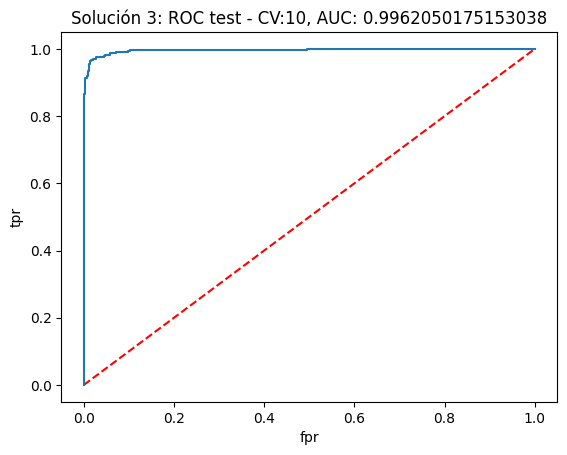

In [34]:
fpr, tpr, thresholds = roc_curve(test_y.values, prediction_scores[:,1], pos_label = "male")

plt.clf()
plt.plot([0, 1], [0, 1], 'k--', c="red")
plt.plot(fpr, tpr)
plt.title("Solución 3: ROC test - CV:10, AUC: " + str(roc_auc_score(test_y, prediction_scores[:,1])))
plt.xlabel("fpr")
plt.ylabel("tpr")
plt.show()


9. ¿Cuál es el punto de corte a utilizar en producción para que **no** tengamos más de 1% de falsos positivos logrando la mayor cantidad de verdaderos positivos? ¿Cuál es el FPR y TPR asociado a ese punto de corte?

In [35]:
df_metrics = pd.DataFrame({'fpr': fpr, 'tpr': tpr, 'thresholds': thresholds})

In [36]:
df_metrics[df_metrics.fpr < 0.1].sort_values(by="fpr", ascending=False)

,fpr,tpr,thresholds
37,0.097458,0.993737,0.203347
36,0.097458,0.991649,0.203463
35,0.072034,0.991649,0.249137
34,0.072034,0.987474,0.256248
33,0.057203,0.987474,0.305251
32,0.057203,0.981211,0.350085
31,0.046610,0.981211,0.397956
30,0.046610,0.979123,0.411341
28,0.044492,0.977035,0.423701
29,0.044492,0.979123,0.413348


In [37]:
punto_corte = df_metrics[df_metrics.fpr < 0.01].sort_values(by=["fpr", "tpr"], ascending=False).head(1)
punto_corte

,fpr,tpr,thresholds
13,0.008475,0.935282,0.83021


In [38]:
from sklearn.metrics import precision_recall_curve

precision, recall, threshold = precision_recall_curve(test_y, prediction_scores[:,1], pos_label="male")

In [39]:
thresholds_ = np.append(threshold, 1)

In [41]:
precision_recall = pd.DataFrame({'precision': precision, 'recall': recall, 'thresholds': thresholds_})
tpr_fpr = pd.DataFrame({'tpr': tpr, 'fpr': fpr, 'thresholds': thresholds})

metrics = tpr_fpr.merge(precision_recall, how="inner", on="thresholds")
metrics

,tpr,fpr,thresholds,precision,recall
0,0.039666,0.000000,1.000000,1.000000,0.039666
1,0.039666,0.000000,1.000000,1.000000,0.000000
2,0.041754,0.000000,0.999886,1.000000,0.041754
3,0.045929,0.000000,0.999844,1.000000,0.045929
4,0.048017,0.000000,0.999821,1.000000,0.048017
...,...,...,...,...,...
64,1.000000,0.849576,0.000156,0.544318,1.000000
65,1.000000,0.855932,0.000125,0.542469,1.000000
66,1.000000,0.858051,0.000104,0.541855,1.000000
67,1.000000,0.862288,0.000096,0.540632,1.000000


In [42]:
metrics[metrics.fpr < 0.01]

,tpr,fpr,thresholds,precision,recall
0,0.039666,0.000000,1.000000,1.000000,0.039666
1,0.039666,0.000000,1.000000,1.000000,0.000000
2,0.041754,0.000000,0.999886,1.000000,0.041754
3,0.045929,0.000000,0.999844,1.000000,0.045929
4,0.048017,0.000000,0.999821,1.000000,0.048017
5,0.054280,0.000000,0.999792,1.000000,0.054280
6,0.058455,0.000000,0.999687,1.000000,0.058455
7,0.866388,0.000000,0.923527,1.000000,0.866388
8,0.866388,0.002119,0.923022,0.997596,0.866388
9,0.912317,0.002119,0.870821,0.997717,0.912317


10. Utilizando el punto de corte seleccionado en la pregunta anterior genera la matriz de confusión asociada -> Aquellos valores que sean iguales o mayores que el punto de corte seleccionado serán etiquetados como etiqueta positiva. 


In [43]:
punto_corte.thresholds.values[0]

np.float64(0.8302095227076849)

In [44]:
labels_punto_corte = ["male" if prediction >= punto_corte.thresholds.values[0] else "female" 
                      for prediction in prediction_scores[:,1]]

In [45]:
confusion_matrix(test_y, labels_punto_corte)

array([[468,   4],
       [ 31, 448]])

Guarda el modelo para produccion

In [48]:
import joblib

joblib.dump(model,'modelo_entrenado.pkl')

['modelo_entrenado.pkl']

In [57]:
import joblib

modelo_cargado = joblib.load('modelo_entrenado.pkl')

Realiza una prediccion

In [88]:
sample = X.sample(1)

In [89]:
modelo_cargado.predict(sample)

array(['male'], dtype=object)